# K-Means Cluster

## Modules

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Functions

In [15]:
def initialize_centroids(X, k):

    #np.random.seed(12) 
    #random.seed(12) or (literally any no.) is not really necessary here, but it can be set for reproducibility if needed to fine tune hyper parameters and for better training. completely for debugging pupose, like to check why are certain choice of random values caused the models to perform poorly compared to other random values..
    centroids=np.random.choice(X.shape[0], k, replace=False)
    return X[centroids]

def get_labels(X, centroids):

    diff=X[:,None,:]-centroids[None,:,:]
    dist=np.sqrt(np.sum(diff**2, axis=2))
    labels=np.argmin(dist, axis =1)
    return labels

def update_centroids(X, labels, k):

    num_features=X.shape[1]
    centroids=np.zeros((k, num_features))
    for i in range(k):
        cluster_points=X[labels==i]
        if len(cluster_points)>0:
            centroids[i]=np.mean(cluster_points,axis=0)
    return centroids

def run_kmeans(X, k, num_iterations=100):
    centroids=initialize_centroids(X, k)
    for i in range(num_iterations):
        lables=get_labels(X, centroids)
        centroids=update_centroids(X, lables, k)

    return lables, centroids

def calculate_wcss(X, k, labels, centroids):
    wcss=0
    for i in range(k):
        cluster_points=X[labels==i]
        diff=cluster_points-centroids[i]
        wcss+=np.sum(np.sum(diff**2, axis=1))
    return wcss

def elbow_plot(X, max_k=10):
    #seeding can help as the plot has chance to be noisy.
    wcss_hist=[]
    for i in range(1, max_k+1):
        lables, centroids= run_kmeans(X, i )
        wcss= calculate_wcss(X, i, lables, centroids)
        wcss_hist.append(wcss)

    plt.plot(range(1,max_k+1), wcss_hist, marker='x')
    plt.title("Elbow PLot")
    plt.xlabel('K')
    plt.ylabel('WCSS')
    plt.grid(True)
    plt.show()


### Notes:

1. Initialize centroid function:- 
* basically randomly selects k centroids from the dataframe.
* the number of centroids are user defined. usually is taken as the elbow of the cluster graph where starting from k+1, the convergence drastically slows down.
* the purpose of random.seed(12) is that it produces a random seed so the same random choice can be made by the model every time it runs with that seed. now this is usefull as it helps test the hyperparameters such as k and the number of iterations against a stable baseline. ONce the model performs well in that seed, we change the seed number to get a new set of fixed random choices. then test the model again with these fixed k values and check if the previous model was a lucky creation. Finally when it holds on with all the seeds, we can confirm the model was not a fluke and test in an unseeded run. Its purely for convinience of debugging purpose. Now this is completely for convinience. Lets say we ran the model without seed 5 times and it works 4 out of 5 times. wt if we want to figure out y the model doesnt work in that one time. for such cases we can lock on to its exact seed and figure out wts wrong.
* now the random.choice() will choose a random array of k means from the dataframe. the choices are basically the index of that row in the dataframe. return=False basically tells if a centroid is chosen it is not replaced into the df for the new selection of k
* finally it returns the rows chosen as centroids.

2. get_labels():-
* to assign a datapoint to a cluster we find the euclidean distance of it to every other centroid and assign it to the centroid that is the closest.
* we can do in the simple nested loop way or in a much more complicated but computationally light broadcasting method. in which we convert the data point array and centroid array into 3d array of equal dimensions and subtract. this is done by duplicated each row for every centroid and centroids for every row. lets say there are m centroids and n data points each with x features. then the shape of data point is (n,x) and centroids is (m,x). we cannot subtract this directly as firstly n is not = m due to which array sub doesnt work and even if its equal each data point finds distance to a unique centroid. which is not the case if we want to find the closest centroid. hence we put none to convert it to a 3d array, whereX[:, None, :] gets (n,1,x) and centroids[None, :, :] gets (1,m,x). the size 1 here gets stretched when we subtract by numpy to give us (n, m, x) dimensions on both side and hence giving us an array of the differences.
* now the distances squares each value and sums each features where axis=2 drops the the inner sub array giving a single number and new shape (n ,m) and sqrt of each value is found.
* arg min takes the smallest value in each row and returns its index which is basically which cluster it blongs to. it will output a 1d array (n,) removing the axis =1 which belonged to each centroid as the smallest centroid is now found.

3. update_centroids():-
* array for centroids filled with zeroes containing a row for each k and column for each feature. this is to hold where each data point belong to.
* then the loop goes through each cluster where if the data point belongs to that cluster, it gets added to the 2d array cluster points. if there is atleast a value in cluster points such that there is atleast one row belongs to that cluster, it averages down the values of each column down to a single number which is then appended to the clusters array.
* returns the new centroid after getting the means fo the cluster.

4. run_kmeans():=
* this is the main function.
* first we intialize a random set of k centroids and get an array of their indices.
* now we run a loop for the number of interations described by the user. in which we run the cluster assign function to get labels which is a array in which each data point to assigned to a cluster and finally the overall mean of all assigned data points in each cluster is taken as the new centroids. this goes on for the num of iterations.

5. calculate_wcss:-
* wcss is basically how far the points are from the centroids and the smaller it is the better the clusters are.
* for doing this first we run a loop for each cluster in which we find the difference between each assigned data point and its cluster. then we find the norm basically the sqrt of sum of the square of each feature. this returns a 1d array for the norm of each data points. now each of these norms are squared and added up to get the final wcss value for each cluster. then these are added up for an overall final wcss.

6. elbow_plot():-
* this is basically to find which k will give the best result.
* first we take a list of wcss values if ran clustering for each k value and append then to the list.
* then we plot the wcss list against the k (1-max k) to get an elbow plot. where the plot takes a sharp turn is the optimal k.

## Body

to find optimal k


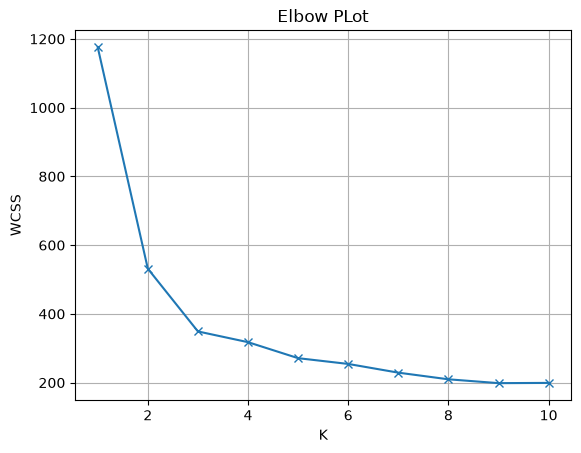

Final centroids are:  [[-0.26303558 -0.30241028  0.39555882 -0.40694053 -0.10323575 -0.68167948
  -0.736868  ]
 [-1.05161688 -1.02185771 -1.04775453 -0.89421374 -1.1260484   0.83648802
  -0.58183174]
 [ 1.16760211  1.18058542  0.51683168  1.17300764  1.07484987 -0.05294032
   1.22731801]]
AVg:
train-  2.0719757234494467
test-  2.4370364502477795


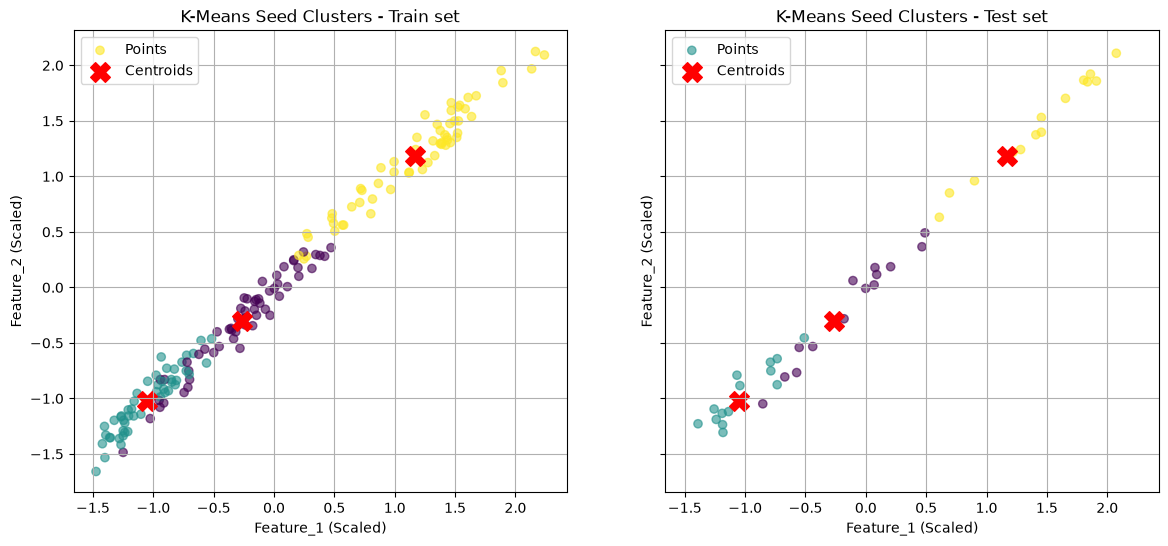

In [16]:
df=pd.read_csv("seeds_data.csv")
x=df.drop(columns=["Class"]).to_numpy(dtype='float')
x_train, x_test= train_test_split(x, test_size=0.2)
# could add a random state for reproducibility and debugging, as otherwise the split changes every time the code is run, which can make it hard to debug and check for performance of the model.

x_mean=x_train.mean(axis=0)
x_std=x_train.std(axis=0)
x_std[x_std==0]=1

x_train=(x_train-x_mean)/x_std
x_test=(x_test-x_mean)/x_std

print("to find optimal k")
elbow_plot(x_train, 10)

optimalk=3

lables, centroids= run_kmeans(x_train, optimalk, 1000)
print("Final centroids are: ",centroids)

test_labels= get_labels(x_test, centroids)

trainwcss= calculate_wcss(x_train, optimalk, lables, centroids)
testwcss= calculate_wcss(x_test, optimalk, test_labels, centroids)

print("AVg:")
print("train- ", trainwcss/len(x_train))
print("test- ", testwcss/len(x_test))

# code imported from a different source purely to check the functioning of the code.
fig, axes= plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, X_part, labels_part, title in [
    (axes[0], x_train, lables, "Train set"),
    (axes[1], x_test, test_labels, "Test set")]:
    ax.scatter(X_part[:, 0], X_part[:, 1], c=labels_part, cmap="viridis",
               alpha=0.6, label="Points")
    ax.scatter(centroids[:, 0], centroids[:, 1], c="red",
               marker="X", s=200, label="Centroids")
    ax.set_title(f"K-Means Seed Clusters - {title}")
    ax.set_xlabel(df.columns[0] + " (Scaled)")
    ax.set_ylabel(df.columns[1] + " (Scaled)")
    ax.legend()
    ax.grid(True)

plt.show()







# HOw the body works:
1. The df is split into x_train and x_test as the same csv file is used for training and testing. Right now its a 80-20 split.
2. then we do zscore normalization by taking the mean values and standard deviation of train set. then the formula (x-x_mean)/x_standardeviation is used to zscore normalize the data.
3. Then we run get optimal k mean value function to plot an elbow plot. from this we can see how each k mean value has performed.
4. we consider the optimal value from the elbow from graph by checking out where the graph sharply converges. this value is used to run k means function to get the final centroids and the labels where each data point is assigned to a centroid.
5. we then use these centroids to assign clusters for each data point in the test array.
6. finally we calculate the wcss score of the model to check how close the test points are from the clusters they are assigned to and find the average wcss value.
7. ive imported a scatter plot visualization method to check how effectively my model runs.

# DBScan

## Functions

In [17]:
def distances(X ):
    dist=np.zeros((X.shape[0],X.shape[0]))
    for i in range(X.shape[0]):
        for j in range(X.shape[0]):
            square_sum=0
            for features in range(X.shape[1]):
                diff=X[i,features]-X[j,features]
                square_sum+=diff**2
            dist[i,j]=np.sqrt(square_sum)
    return dist

def run_dbscan(X, min_samples, d):
    dist=distances(X)
    neighbours=[]
    for i in range(X.shape[0]):
        neighbour_points=np.where(dist[i]<=d)[0]
        neighbours.append(neighbour_points)

    core_points=[]
    for i in range(X.shape[0]):
        if len(neighbours[i]>=min_samples):
               core_points.append(i)

    labels=np.full(X.shape[0],-1)
    cluster_id=0
    for i in range(X.shape[0]):
        if labels[i]!=-1 or i not in core_points:
            continue

        labels[i]=cluster_id
        cluster_points=[i]
        while cluster_points:
            c=cluster_points.pop()
            for j in neighbours[c]:
                
                if labels[j]==-1:
                    labels[j]=cluster_id
                    if j in core_points:
                        cluster_points.append(j)
                    
        cluster_id+=1

    return labels

#experimental
def k_distance_plot(X, k):
    dists=distances(X)
    sorted_rows = np.sort(dists, axis=1)         # each row sorted, column 0 is the point itself
    kth_distance = np.sort(sorted_rows[:, k])

    plt.plot(kth_distance)
    plt.title('Distance Plot, to check for d')
    plt.xlabel('Points (sorted)')
    plt.ylabel('Distance to '+ str(k) + 'th nearest point')
    plt.grid(True)
    plt.show()

        
    

### Notes:

1. distance:-
* its used to find the distance of every point to every other point in the dataframe using the euclidean distance.
* this uses loop. first we create a 2d array of dimensions nxn to store the distance of each each point wrt to every other point. and then loop is run to find the euclidean distance and finding the difference between the features of 2 points squaring it adding them all up, and finally finding the sqrt.
* the final array of distances are exported. 
* this is slow and can be fixed by vectorisation using broadcasting and is smthing ill fix later on.
* next we run a loop to expand the cluster. for this we need a list c to store possible core values to be taken to overlap and cluster_id which is equal to the cluster


2. run_dbscan():-
* the db scan works under the principle where close points are selected based on how many neighbours it overlaps around itif we drew a circle of radius r around it. the number of neighbours and r is user defined. like this it finds all the close points and links them to each other based on their proximity. after that the non close points are incorporated into different clusters if it overlaps a circle draw from a close point. every other points are considered outliers.
* so first we take the array of all possible distances from compute_distance function.
* now we create a list to store all the neigbours (the points overlapped) of each and every point in the dataset. .where() returns an array eclosed in a tuple. [0] extracts the array from the tuple.
* then we make a list corepoints to store all the corepoint values, basically values that overall a min number of samples predefined by the user.
* then we make a list label to hold the assigned cluster of each point which would start of at -1. basically -1 is noise or the outlier. so all starts as noise and it gets add ed to the cluster its values changes. the loop runs by taking each neighbors of the corepoints and assigning it the cluster id and if the neigbors are corepoints aswell they get added to list their neighbours get assigned to the cluster id and this goes on untill all nieghbouring corepoints for each corepoint under the cluster id is exhausted. then cluster id is incremented and is assigned to the next corepoint not assigned to any of the previous core points and the cycle repeats.
* 

3. k_distance_plot:-
* the code is to plot a plot a k value grpah to get the best value for d, or the optimum radius to be used by sorting its distances to all other points and selecting the distance to its k-th nearest neighbor.
* first we take a 2d array of the distance of every single point to every other points in the dataframe, then we sort each of the rows based on its closeness to the each point.
* then we take the kth point basically the kth closest point to each points and graph it wrt to the values in it.


## Body

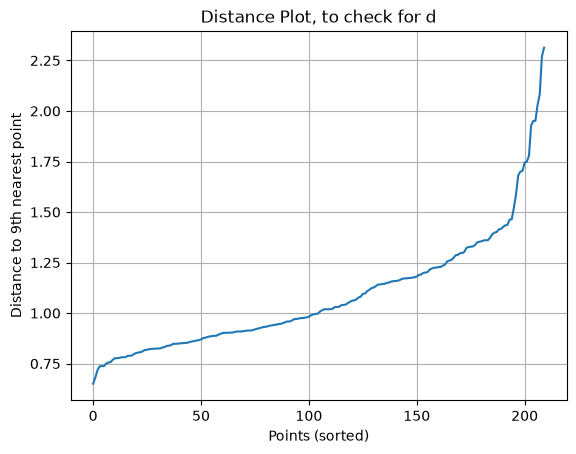

Clusters found:  9
Noise points:  0


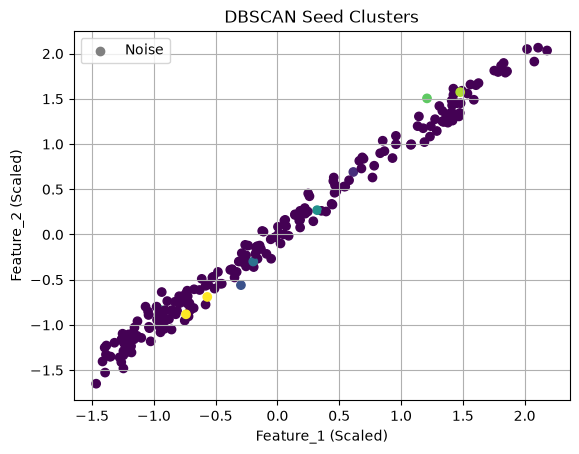

Adjusted Rand Index vs Class: 0.00011151243499640985


In [18]:
from sklearn.metrics import adjusted_rand_score

df=pd.read_csv("seeds_data.csv")
x=df.drop(columns=["Class"]).to_numpy(dtype='float')
y=df["Class"].to_numpy(dtype='int')
x_mean=x.mean(axis=0)
x_std=x.std(axis=0)
x_std[x_std==0]=1
x=(x-x_mean)/x_std

min_samples = 10
k_distance_plot(x, min_samples-1)    

radius = 1.0   # depends on plt
labels = run_dbscan(x, min_samples, radius)

n_clusters=labels.max()+1
n_noise=np.sum(labels==-1)
print("Clusters found: ", n_clusters)
print("Noise points: ", n_noise)

# imported plot from source (noise in grey) to check how good the clustering is, and how many points are noise, and how many clusters are found.

noise=labels==-1
plt.scatter(x[noise,0], x[noise,1], c="grey", label="Noise")
plt.scatter(x[~noise,0], x[~noise,1], c=labels[~noise], cmap="viridis")
plt.title("DBSCAN Seed Clusters")
plt.xlabel(df.columns[0]+" (Scaled)")
plt.ylabel(df.columns[1]+" (Scaled)")
plt.legend()
plt.grid(True)
plt.show()

# adjusted rand index to check how well the clustering is done, and how well it matches with the actual class labels.
print("Adjusted Rand Index vs Class:", adjusted_rand_score(y, labels))

# HOw the body works:
